
# Exploratory Data Analysis — CardioClassify

## Objective
This notebook explores the UCI Arrhythmia dataset before machine
learning model training.

The analysis covers:
1. Original 16-class distribution and the binary class distribution.
2. Relationships between selected numerical features and the target.
3. Feature correlations using a readable subset of features.
4. Differences in feature distributions between Normal and Arrhythmia records.

## Dataset
- Source: UCI Machine Learning Repository — Arrhythmia dataset.
- Original data: 452 records, 279 input features, and one target column.
- Class 16 is excluded from the binary classification task.
- Binary target: 0 = Normal; 1 = Arrhythmia.

EDA is descriptive. Model performance is evaluated separately using
stratified 5-fold cross-validation.


In [14]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project root whether Jupyter starts in the root or notebook folder.
ROOT = Path.cwd()

if not (ROOT / "Data" / "arrhythmia.data").exists():
    ROOT = ROOT.parent

RAW_PATH = ROOT / "Data" / "arrhythmia.data"
CLEAN_PATH = ROOT / "Data" / "clean_data.csv"
IMAGE_DIR = ROOT / "Image"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Consistent appearance across all figures
sns.set_theme(style="whitegrid", context="notebook")
NORMAL_COLOR = "#4C78A8"
ARRHYTHMIA_COLOR = "#E45756"

# Original data: needed for the original class distribution
raw = pd.read_csv(RAW_PATH, header=None, na_values="?")

# Cleaned data: used for all binary-label analyses
clean = pd.read_csv(CLEAN_PATH)

# The target column retains its original index (279) in the CSV header.
target_col = "279" if "279" in clean.columns else clean.columns[-1]

# Convert all columns to numeric values where possible
clean = clean.apply(pd.to_numeric, errors="coerce")

print("Original dataset shape:", raw.shape)
print("Cleaned dataset shape:", clean.shape)
print("Target column:", target_col)

display(clean.head())

assert raw.shape == (452, 280)
assert len(clean) == 430
assert clean[target_col].value_counts().to_dict() == {0: 245, 1: 185}


Original dataset shape: (452, 280)
Cleaned dataset shape: (430, 262)
Target column: 279


,0,1,2,3,4,5,6,7,8,9,...,269,270,271,272,273,275,276,277,278,279
0,75,0,190.0,80.0,91,193,371,174,121,-16,...,-0.3,0.0,9.0,-0.9,0.0,0.9,2.9,23.3,49.4,1
1,56,1,165.0,64.0,81,174,401,149,39,25,...,-0.5,0.0,8.5,0.0,0.0,0.2,2.1,20.4,38.8,1
2,54,0,172.0,95.0,138,163,386,185,102,96,...,0.9,0.0,9.5,-2.4,0.0,0.3,3.4,12.3,49.0,1
3,55,0,175.0,94.0,100,202,380,179,143,28,...,0.1,0.0,12.2,-2.2,0.0,0.4,2.6,34.6,61.6,0
4,75,0,190.0,80.0,88,181,360,177,103,-16,...,-0.4,0.0,13.1,-3.6,0.0,-0.1,3.9,25.4,62.8,1


Class distribution before and after conversion

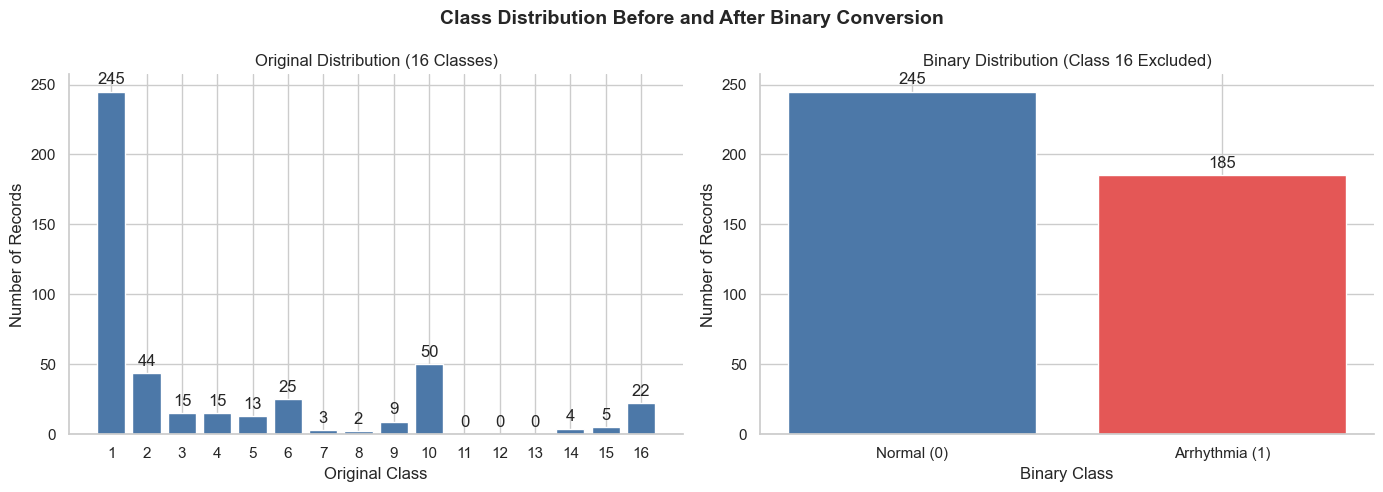

Original total: 452
Class 16 records: 22
Binary total: 430
Binary counts:
 279
0    245
1    185
Name: count, dtype: int64


In [15]:

# Original class counts, explicitly showing all labels from 1 to 16
original_target = raw.iloc[:, -1].dropna().astype(int)

original_counts = (
    original_target.value_counts()
    .reindex(range(1, 17), fill_value=0)
)

# Binary class counts from the cleaned data
binary_counts = clean[target_col].astype(int).value_counts().reindex(
    [0, 1], fill_value=0
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before: original classes
axes[0].bar(
    original_counts.index,
    original_counts.values,
    color=NORMAL_COLOR
)
axes[0].set_title("Original Distribution (16 Classes)")
axes[0].set_xlabel("Original Class")
axes[0].set_ylabel("Number of Records")
axes[0].set_xticks(range(1, 17))

# After: binary classes
axes[1].bar(
    ["Normal (0)", "Arrhythmia (1)"],
    binary_counts.values,
    color=[NORMAL_COLOR, ARRHYTHMIA_COLOR]
)
axes[1].set_title("Binary Distribution (Class 16 Excluded)")
axes[1].set_xlabel("Binary Class")
axes[1].set_ylabel("Number of Records")

for ax in axes:
    ax.bar_label(ax.containers[0], padding=3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Class Distribution Before and After Binary Conversion",
             fontsize=14, fontweight="bold")
fig.tight_layout()

fig.savefig(
    IMAGE_DIR / "class_distribution_before_after.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Original total:", original_counts.sum())
print("Class 16 records:", original_counts.loc[16])
print("Binary total:", binary_counts.sum())
print("Binary counts:\n", binary_counts)


Correlation heatmap

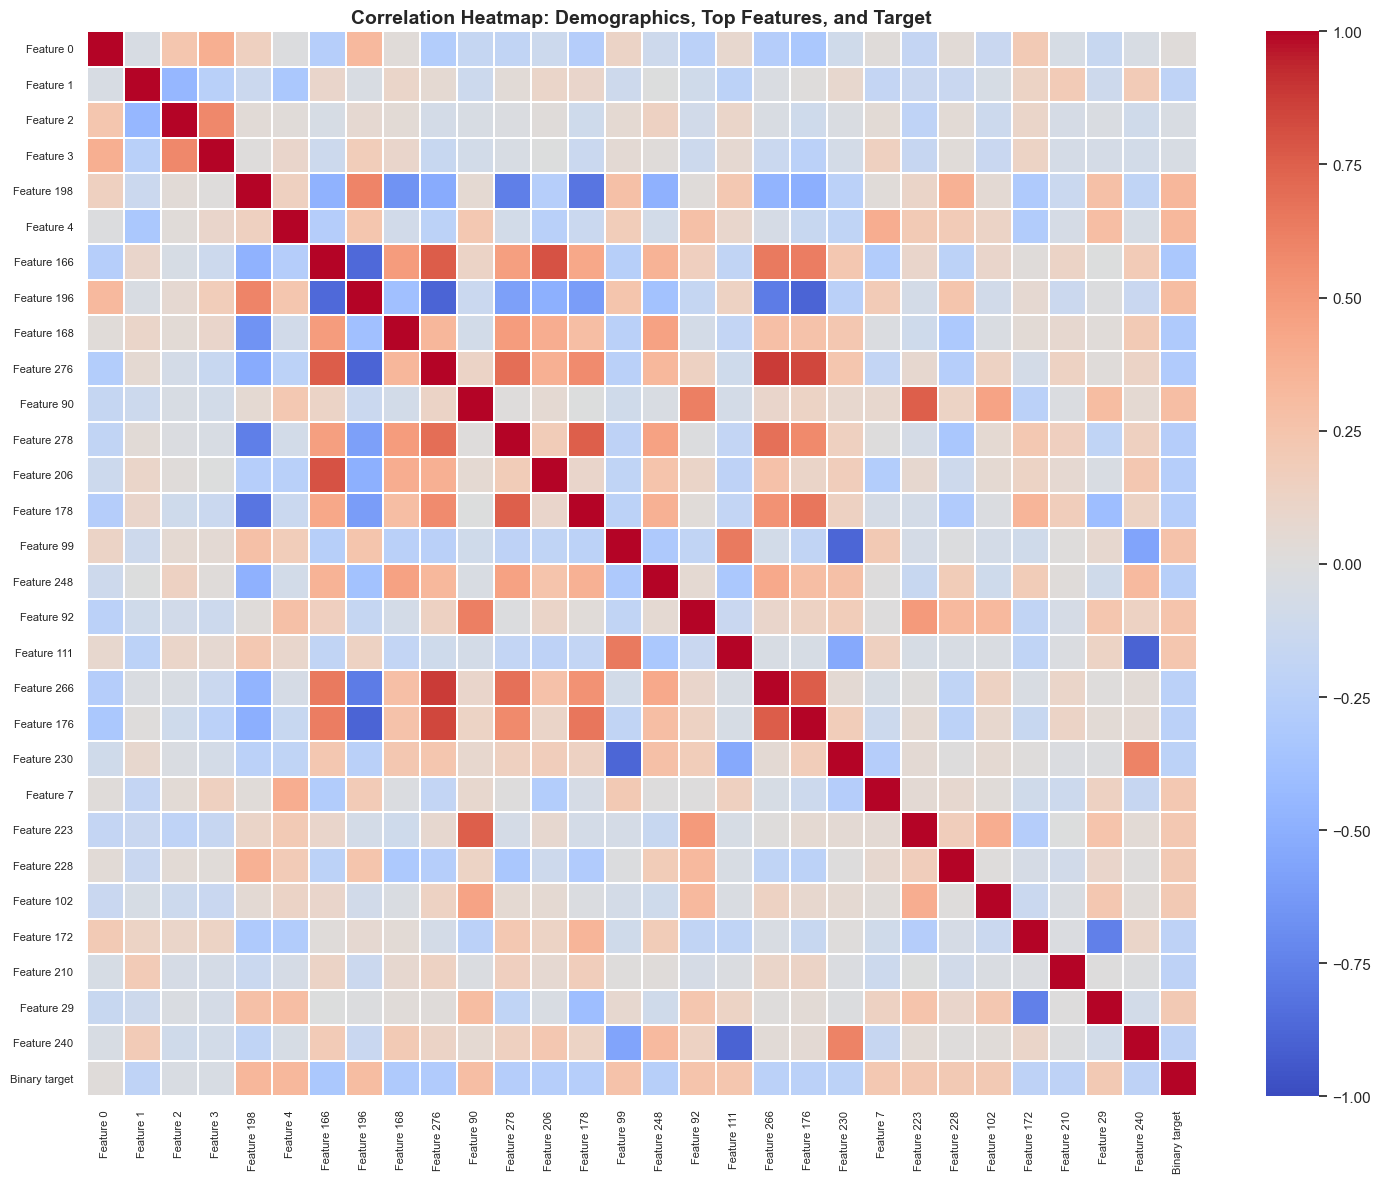

Number of selected predictors: 29
Top features by absolute target correlation:


,Pearson correlation
198,0.339867
4,0.332516
166,-0.322858
196,0.304649
168,-0.302948
276,-0.296778
90,0.294069
278,-0.272688
206,-0.265459
178,-0.263823


In [16]:

# Work only with numeric columns; the target remains excluded from predictors.
numeric_data = clean.select_dtypes(include="number").copy()

target_corr = (
    numeric_data.corr(method="pearson")[target_col]
    .drop(target_col)
    .dropna()
)

# The original first four columns are age, sex, height, and weight.
demographic_cols = [
    col for col in ["0", "1", "2", "3"]
    if col in numeric_data.columns and col in target_corr.index
]

# Top 25 predictors by absolute correlation with the binary target
top_features = (
    target_corr.abs()
    .sort_values(ascending=False)
    .head(25)
    .index.tolist()
)

# Combine demographic features with top-correlated features, without duplicates.
selected_features = list(dict.fromkeys(demographic_cols + top_features))

heatmap_data = numeric_data[selected_features + [target_col]].copy()

# Make labels readable while preserving the original column indices.
label_map = {
    col: f"Feature {col}" for col in selected_features
}
label_map[target_col] = "Binary target"

heatmap_data = heatmap_data.rename(columns=label_map)
corr_matrix = heatmap_data.corr(method="pearson")

plt.figure(figsize=(15, 12))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.15,
    annot=False
)

plt.title(
    "Correlation Heatmap: Demographics, Top Features, and Target",
    fontsize=14,
    fontweight="bold"
)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "feature_correlation_heatmap.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Number of selected predictors:", len(selected_features))
print("Top features by absolute target correlation:")
display(target_corr.loc[top_features].to_frame("Pearson correlation")
        .sort_values("Pearson correlation", key=abs, ascending=False))


Missing-values chart

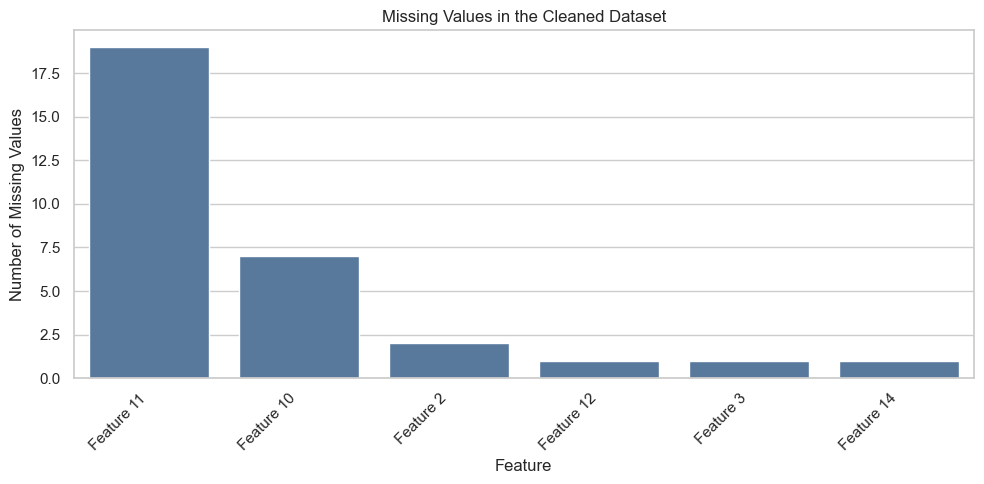

Total missing feature values: 31


,Missing count
11,19
10,7
2,2
12,1
3,1
14,1


In [17]:

missing_counts = (
    clean.drop(columns=[target_col])
    .isna()
    .sum()
    .sort_values(ascending=False)
)

missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(10, 5))

if len(missing_counts) > 0:
    sns.barplot(
        x=[f"Feature {c}" for c in missing_counts.index],
        y=missing_counts.values,
        color=NORMAL_COLOR
    )
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Number of Missing Values")
    plt.xlabel("Feature")
    plt.title("Missing Values in the Cleaned Dataset")
    plt.tight_layout()

    plt.savefig(
        IMAGE_DIR / "missing_values.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()
else:
    print("No missing feature values remain.")

print("Total missing feature values:", int(missing_counts.sum()))
display(missing_counts.to_frame("Missing count"))


Compare feature distributions between classes

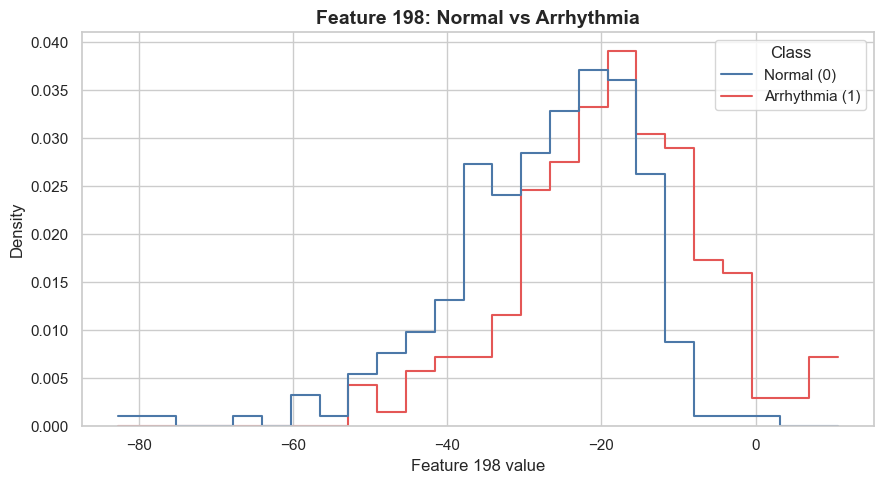

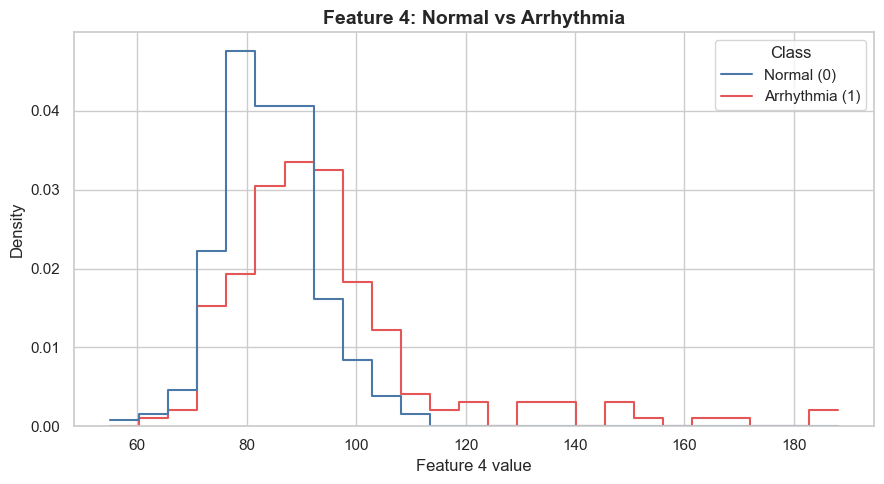

Features plotted: ['198', '4']


In [18]:

# Prefer features with enough observations and variation to make
# distribution comparisons meaningful.
distribution_candidates = [
    feature for feature in top_features
    if numeric_data[feature].notna().sum() >= 20
    and numeric_data[feature].nunique(dropna=True) >= 5
]

# Fallback if fewer than two features meet the stricter criterion.
if len(distribution_candidates) < 2:
    distribution_candidates = [
        feature for feature in top_features
        if numeric_data[feature].notna().sum() >= 20
        and numeric_data[feature].nunique(dropna=True) > 1
    ]

if len(distribution_candidates) < 2:
    raise ValueError(
        "Fewer than two suitable features were found. "
        "Inspect the selected feature columns."
    )

distribution_features = distribution_candidates[:2]

plot_data = clean.copy()
plot_data["Class"] = plot_data[target_col].map({
    0: "Normal (0)",
    1: "Arrhythmia (1)"
})

palette = {
    "Normal (0)": NORMAL_COLOR,
    "Arrhythmia (1)": ARRHYTHMIA_COLOR
}

for i, feature in enumerate(distribution_features, start=1):
    feature_data = plot_data[[feature, "Class"]].dropna()

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=feature_data,
        x=feature,
        hue="Class",
        hue_order=["Normal (0)", "Arrhythmia (1)"],
        palette=palette,
        bins=25,
        stat="density",
        common_norm=False,
        element="step",
        fill=False
    )

    plt.title(
        f"Feature {feature}: Normal vs Arrhythmia",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel(f"Feature {feature} value")
    plt.ylabel("Density")
    plt.tight_layout()

    plt.savefig(
        IMAGE_DIR / f"feature_distribution_{i}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

print("Features plotted:", distribution_features)


Final checks and saved figures

In [19]:

print("EDA verification")
print("-" * 40)
print("Original rows:", len(raw))
print("Original columns:", raw.shape[1])
print("Cleaned rows:", len(clean))
print("Cleaned columns:", clean.shape[1])
print("Normal records:", int((clean[target_col] == 0).sum()))
print("Arrhythmia records:", int((clean[target_col] == 1).sum()))
print("Missing feature values:", int(clean.drop(
    columns=[target_col]
).isna().sum().sum()))

expected_figures = [
    "class_distribution_before_after.png",
    "feature_correlation_heatmap.png",
    "missing_values.png",
    "feature_distribution_1.png",
    "feature_distribution_2.png"
]

print("\nExpected figure files:")
for filename in expected_figures:
    path = IMAGE_DIR / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")


EDA verification
----------------------------------------
Original rows: 452
Original columns: 280
Cleaned rows: 430
Cleaned columns: 262
Normal records: 245
Arrhythmia records: 185
Missing feature values: 31

Expected figure files:
class_distribution_before_after.png: FOUND
feature_correlation_heatmap.png: FOUND
missing_values.png: FOUND
feature_distribution_1.png: FOUND
feature_distribution_2.png: FOUND


## EDA Findings and Conclusion

The exploratory analysis examined the original class distribution, binary class distribution, feature correlations, missing values, and selected feature distributions.

The original dataset contained 452 records across 16 class labels. After excluding class 16, 430 records remained: 245 Normal records and 185 Arrhythmia records.

The correlation heatmap provides an overview of the linear relationships among selected demographic features, features associated with the binary target, and the target itself. The distribution plots allow visual comparison of selected features between the two classes.

Missing values remain in a small number of feature columns and will be handled through median imputation within the modelling pipeline.

EDA is descriptive and does not establish predictive performance. The next stage will compare six machine learning models, with and without PCA, using stratified 5-fold cross-validation. Accuracy, precision, recall and F1-score will be used for evaluation, with particular attention to Arrhythmia-class recall and F1-score.
